# Mesa County Real Estate Sales: Price Trends and Property Characteristics
**EDS 6340 — Introduction to Data Science | Team #6**  
**Team members:** Hoang Dang Pham, Beatriz Ordonez, Krisgina Truc Pham, Greyson Newton  
**Source:** [Mesa County Assessor — Property Sales Search](https://emap.mesacounty.us/Assessor_Sales_Lookup/)

## 1. Introduction

### Problem statement
Real estate prices can vary depending on factors such as location, property size, building age, and market conditions. This project analyzes property sales data from Mesa County, Colorado, to explore how sale prices have changed over time and how different property characteristics relate to these differences. Through statistical analysis and data visualization, the project aims to identify meaningful patterns and trends in the local real estate market.

### Objectives
1. Collect at least 15,000 real-estate transaction records with at least 7 original variables from HTML.
2. Check data quality and prepare a reliable dataset while keeping the raw data unchanged.
3. Compare sale prices across years, residential property types, and locations.
4. Explore relationships between prices and house characteristics, including size, bedrooms, bathrooms, and construction year.
5. Summarize observations using descriptive statistics and visualizations.

### Description of the original variables
| Column | Description |
|---|---|
| Parcel Number | Property parcel identifier |
| Account Number | Assessor account identifier |
| Reception No./Book Page | Recorded document reference |
| Address | Property street address |
| Sale Price | Recorded transaction amount |
| Time Adjusted Sale Price | Sale price adjusted by the source's timing method |
| Sale Date | Date of sale |
| Grantee | Recorded buyer/recipient |
| Grantor | Recorded seller/transferrer |
| Actual Value | Assessor's displayed actual value (not necessarily the sale price) |
| Qualification Code | Source-assigned transaction qualification category |
| Neighborhood | Source's property neighborhood classification |
| Economic Area | Broader economic area |
| Property Use | Property category (residential, townhouse, commercial, etc.) |
| Total Heated Sq Ft | Heated building area in square feet |
| Price by Heated SQFT | Source-reported sale price per heated square foot |
| Aprox. Acres | Approximate parcel area in acres |
| Architectural Style 1st Building | Main building's style |
| Total # Buildings | Number of buildings on record |
| Earliest Effective Year Built | Assessor's effective construction-year measure |
| Actual Year Built | Source's recorded construction year |
| PropUse | Numeric property-use category |
| Bed | Number of bedrooms |
| Bath | Number of bathrooms |
| SourceFile | Added during extraction to track the HTML file of origin |

**Unit of analysis:** Each row in this dataset represents a recorded property sale. The same property may appear multiple times if it was sold in different years, so these records are not considered duplicates. However, some records may share the same property, sale date, and sale price but have different document numbers. These records will be flagged for further review instead of being automatically removed during data cleaning.

## 2. Importing Libraries

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

pd.set_option('display.max_columns', 30)

**Observation**  
We use BeautifulSoup to read the HTML table, Pandas and NumPy to organize and examine the records, and Matplotlib for a few basic exploration charts.

## 3. Data Scraping

The Mesa County website displays property sales in an interactive table. We selected non-overlapping sale-date ranges in the browser, then exported the already-loaded HTML rows to local  `mesa_sales_*.html` files.

Using BeautifulSoup, we extract all original columns from the saved HTML files and combine them with Pandas.

**Input:** Place the exported `mesa_sales_*.html` files in the same folder as this notebook.

### 3.1 Read the saved HTML tables

In [ ]:
html_files = sorted(Path('data').glob('mesa_sales_*.html'))
print('HTML files:', [file.name for file in html_files])

HTML files: ['mesa_sales_2022_2022.html', 'mesa_sales_2023_2024.html', 'mesa_sales_2025_2026.html']


**Observation**  
The original collection used three non-overlapping date-range HTML exports. Keeping their filenames allows us to trace each transaction back to its source.

### 3.2 Extract the rows and combine the data

In [11]:
parts = []

for file in html_files:
    # Read the HTML file and find the sales table
    soup = BeautifulSoup(file.read_text(encoding='utf-8'), 'html.parser')
    table = soup.find('table')

    # Extract column names and all data rows
    columns = [th.get_text(strip=True) for th in table.select('thead th')]
    rows = [
        [td.get_text(' ', strip=True) for td in tr.select('td')]
        for tr in table.select('tbody tr')
    ]

    # Convert the rows into a DataFrame and track the source file
    df = pd.DataFrame(rows, columns=columns)
    df['SourceFile'] = file.name
    parts.append(df)

# Combine all HTML tables into one dataset
raw = pd.concat(parts, ignore_index=True)

print('Combined dataset:', raw.shape)
display(raw.head(3))


Combined dataset: (15355, 25)


,Parcel Number (Click for map),Account Number (Click for details),Reception No./Book Page (Click for Doc.),Address,Sale Price,Time Adjusted Sale Price,Sale Date,Grantee,Grantor,Actual Value,Qualification Code,Neighborhood,Economic Area,Property Use,Total Heated Sq Ft,Price by Heated SQFT,Aprox. Acres,Architectural Style 1st Building,Total # Buildings,Earliest Effective Year Built,Actual Year Built,PropUse,Bed,Bath,SourceFile
0,243523300104,R000022,3038104,2423 16 RD,$475000,$475000,07/12/2022,HANSON GARY R JR,PETERSEN STEVEN P,"$447,230",Q,AREA 27 M&B AYB 2001-2020; 2001-2500SF,Loma/Mack County West,Residential,2070,$229.47,18.17,-IRC/PREFAB-,1,2013,2013,1000,3,2,mesa_sales_2022_2022.html
1,244526201007,R000289,3014793,4642 BASS LAKE CT,$72000,$72000,01/04/2022,WILLOW LEROY,MYERS MICHAEL L,"$633,200",QF,Bass Lake Estates,Outlying North & East,Residential,3047,$23.63,1.64,-TWO STORY-,1,2024,2024,1000,4,3.5,mesa_sales_2022_2022.html
2,244526201015,R000297,3023979,4649 BASS LAKE CT,$690000,$690000,03/18/2022,SMITH DAVID R,PARSONS JON P,"$626,420",QF,Bass Lake Estates,Outlying North & East,Residential,4141,$166.63,1.85,-TWO STORY-,1,1999,1999,1000,5,3.2,mesa_sales_2022_2022.html


**Observation**  
All HTML table rows are combined into one DataFrame, retaining the original 24 website columns. The additional SourceFile column records which export each row came from.

### 3.3 Save the original dataset

In [ ]:
raw.to_csv('data/mesa_sales_raw.csv', index=False, encoding='utf-8-sig')
print(f'Rows: {len(raw):,} | Website columns: {len(raw.columns) - 1}')
print('Meets project minimum:', len(raw) >= 15_000 and len(raw.columns) - 1 >= 7)

Rows: 15,355 | Website columns: 24
Meets project minimum: True


**Observation**  
The downloaded sales data contains 15,355 records and 24 original website fields, so the scraping output meets both numeric minimums. We preserve this file for the submission and perform later changes only on a copy.

## 4. Loading (Reading) the Dataset

In [ ]:
df = pd.read_csv('data/mesa_sales_raw.csv', dtype=str, keep_default_na=False)
work = df.copy(deep=True)
print('Original:', df.shape, '| Working copy:', work.shape)
display(work.head(3))

Original: (15355, 25) | Working copy: (15355, 25)


,Parcel Number (Click for map),Account Number (Click for details),Reception No./Book Page (Click for Doc.),Address,Sale Price,Time Adjusted Sale Price,Sale Date,Grantee,Grantor,Actual Value,Qualification Code,Neighborhood,Economic Area,Property Use,Total Heated Sq Ft,Price by Heated SQFT,Aprox. Acres,Architectural Style 1st Building,Total # Buildings,Earliest Effective Year Built,Actual Year Built,PropUse,Bed,Bath,SourceFile
0,243523300104,R000022,3038104,2423 16 RD,$475000,$475000,07/12/2022,HANSON GARY R JR,PETERSEN STEVEN P,"$447,230",Q,AREA 27 M&B AYB 2001-2020; 2001-2500SF,Loma/Mack County West,Residential,2070,$229.47,18.17,-IRC/PREFAB-,1,2013,2013,1000,3,2,mesa_sales_2022_2022.html
1,244526201007,R000289,3014793,4642 BASS LAKE CT,$72000,$72000,01/04/2022,WILLOW LEROY,MYERS MICHAEL L,"$633,200",QF,Bass Lake Estates,Outlying North & East,Residential,3047,$23.63,1.64,-TWO STORY-,1,2024,2024,1000,4,3.5,mesa_sales_2022_2022.html
2,244526201015,R000297,3023979,4649 BASS LAKE CT,$690000,$690000,03/18/2022,SMITH DAVID R,PARSONS JON P,"$626,420",QF,Bass Lake Estates,Outlying North & East,Residential,4141,$166.63,1.85,-TWO STORY-,1,1999,1999,1000,5,3.2,mesa_sales_2022_2022.html


**Observation**  
The working copy keeps all collected values unchanged at this stage. Cleaning `work` will not modify the original CSV or the `df` DataFrame.

## 5. Exploratory Data Analysis (EDA)

### 5A. Basic Data Exploration

#### 5A.1 Dataset attributes and data types

In [22]:
print('Shape:', work.shape)
print('Number of values:', work.size)
print('All columns:', work.columns.tolist())
work.info()

Shape: (15355, 25)
Number of values: 383875
All columns: ['Parcel Number (Click for map)', 'Account Number (Click for details)', 'Reception No./Book Page (Click for Doc.)', 'Address', 'Sale Price', 'Time Adjusted Sale Price', 'Sale Date', 'Grantee', 'Grantor', 'Actual Value', 'Qualification Code', 'Neighborhood', 'Economic Area', 'Property Use', 'Total Heated Sq Ft', 'Price by Heated SQFT', 'Aprox. Acres', 'Architectural Style 1st Building', 'Total # Buildings', 'Earliest Effective Year Built', 'Actual Year Built', 'PropUse', 'Bed', 'Bath', 'SourceFile']
<class 'pandas.DataFrame'>
RangeIndex: 15355 entries, 0 to 15354
Data columns (total 25 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   Parcel Number (Click for map)             15355 non-null  str  
 1   Account Number (Click for details)        15355 non-null  str  
 2   Reception No./Book Page (Click for Doc.)  15355 non-null  st

**Observation**  
The 15,355-row dataset has 25 fields, including the source filename. Since it was scraped as text, values such as dates, dollars, and square footage need conversion before numerical analysis.

#### 5A.2 Missing values and repeated records

In [25]:
# Count empty values in each column
missing = work.apply(lambda col: col.str.strip().eq('').sum())
missing = missing[missing > 0].sort_values(ascending=False)

# Display columns with missing values
display(pd.DataFrame({
    'Empty Values': missing,
    'Empty %': (missing / len(work) * 100).round(2)
}))

# Check for duplicate records
print('Exact duplicates:', work.duplicated().sum())

# Check for potentially repeated sales
sale_cols = ['Parcel Number (Click for map)', 'Sale Date', 'Sale Price']
print('Potential repeated sales:', work.duplicated(subset=sale_cols, keep=False).sum())

,Empty Values,Empty %
Bed,467,3.04
Bath,462,3.01
Architectural Style 1st Building,27,0.18
Reception No./Book Page (Click for Doc.),3,0.02


Exact duplicates: 0
Potential repeated sales: 18


**Observation**  
The dataset has relatively few missing values. The Bed and Bath columns have the most missing entries, with 467 (3.04%) and 462 (3.01%), respectively. There are no exact duplicate rows, but 18 additional records share the same parcel number, sale date, and sale price as another record. These potential repeated sales will be reviewed during data cleaning to avoid removing valid transactions.

#### 5A.3 Initial descriptive summary

In [28]:
# Convert sale prices and dates to the correct data types
price_preview = pd.to_numeric(work['Sale Price'].str.replace(r'[$,]', '', regex=True), errors='coerce')
date_preview = pd.to_datetime(work['Sale Date'], format='%m/%d/%Y', errors='coerce')

# Display the date range and median sale price
print('Sale date range:', date_preview.min().date(), 'to', date_preview.max().date())
print(f'Median sale price: ${price_preview.median():,.0f}')

# Display sale price statistics
display(price_preview.describe().round(0).to_frame('Sale Price'))

# Display the 12 most common property types
display(work['Property Use'].value_counts().head(12).to_frame('Rows'))


Sale date range: 2022-01-02 to 2026-09-25
Median sale price: $383,500


,Sale Price
count,15355.0
mean,425470.0
std,288804.0
min,0.0
25%,286550.0
50%,383500.0
75%,510000.0
max,9890900.0


,Rows
Property Use,
Residential,12684
Townhouse,1100
Condo,555
Agricultural,452
Commercial,303
Duplex/Triplex,97
Multi-Fam 4-8,72
Industrial,62
Multi 9 - Up,13


**Observation**  
The dataset contains 15,355 property sales recorded between January 2022 and September 2026. The median sale price is $383,500, while the mean is higher at $425,470, suggesting that higher-priced properties may be pulling the average upward. Sale prices range from $0 to approximately $9.89 million, indicating some unusual values that may need further investigation. Most transactions are residential properties, followed by townhouses and condos. The dataset also includes agricultural and commercial properties, which we will consider during data cleaning.

### 5B. Univariate, Bivariate, and Multivariate Analysis

#### 5B.1 Data cleaning and type conversion

In [32]:
# Rename columns for easier analysis
rename = {
    'Parcel Number (Click for map)': 'parcel_id',
    'Account Number (Click for details)': 'account_id',
    'Reception No./Book Page (Click for Doc.)': 'reception_id',
    'Address': 'address', 'Sale Price': 'sale_price',
    'Time Adjusted Sale Price': 'time_adjusted_sale_price',
    'Sale Date': 'sale_date', 'Grantee': 'grantee', 'Grantor': 'grantor',
    'Actual Value': 'assessor_actual_value',
    'Qualification Code': 'qualification_code', 'Neighborhood': 'neighborhood',
    'Economic Area': 'economic_area', 'Property Use': 'property_use',
    'Total Heated Sq Ft': 'heated_sqft', 'Price by Heated SQFT': 'price_per_sqft_reported',
    'Aprox. Acres': 'acres',
    'Architectural Style 1st Building': 'architectural_style',
    'Total # Buildings': 'building_count',
    'Earliest Effective Year Built': 'effective_year_built',
    'Actual Year Built': 'year_built', 'PropUse': 'property_use_code',
    'Bed': 'bedrooms', 'Bath': 'bathrooms', 'SourceFile': 'source_file'
}

# Rename columns and remove extra spaces
work = work.rename(columns=rename)
work = work.apply(lambda col: col.str.strip())

# Convert numerical columns
numeric_cols = [
    'sale_price', 'time_adjusted_sale_price', 'assessor_actual_value',
    'heated_sqft', 'price_per_sqft_reported', 'acres', 'building_count',
    'effective_year_built', 'year_built', 'bedrooms', 'bathrooms'
]

work[numeric_cols] = (
    work[numeric_cols]
    .replace(r'[$,]', '', regex=True)
    .apply(pd.to_numeric, errors='coerce')
)

# Convert dates and extract year/month
work['sale_date'] = pd.to_datetime(
    work['sale_date'], format='%m/%d/%Y', errors='coerce'
)

work['sale_year'] = work['sale_date'].dt.year
work['sale_month'] = work['sale_date'].dt.strftime('%Y-%m')

# Display results
print(work[numeric_cols + ['sale_date']].dtypes)
display(work[['sale_price', 'sale_date', 'heated_sqft', 'bedrooms', 'bathrooms']].head())


sale_price                           int64
time_adjusted_sale_price             int64
assessor_actual_value                int64
heated_sqft                          int64
price_per_sqft_reported            float64
acres                              float64
building_count                       int64
effective_year_built                 int64
year_built                           int64
bedrooms                           float64
bathrooms                          float64
sale_date                   datetime64[us]
dtype: object


,sale_price,sale_date,heated_sqft,bedrooms,bathrooms
0,475000,2022-07-12,2070,3.0,2.0
1,72000,2022-01-04,3047,4.0,3.5
2,690000,2022-03-18,4141,5.0,3.2
3,212000,2022-10-13,1110,2.0,1.0
4,255000,2022-10-06,1458,3.0,2.0


**Observation**  
The data types were successfully converted. Sale prices, square footage, building counts, and construction years are now stored as numerical values, while sale dates are stored in datetime format. Bedrooms and bathrooms are stored as floating-point numbers to accommodate missing values and decimal values. These changes make the dataset easier to work with for statistical calculations, comparisons, and visualizations in the following sections.

#### 5B.2 Handle missing or unusual values and remove potential duplicates

In [35]:
# Handle missing and unusual values
work.replace('', np.nan, inplace=True)

placeholder_bath = work['bathrooms'] >= 100
work.loc[placeholder_bath, 'bathrooms'] = np.nan

# Calculate building age at the time of sale
work['year_built_after_sale'] = work['year_built'] > work['sale_year']
work['building_age_at_sale'] = work['sale_year'] - work['year_built']
work.loc[work['year_built_after_sale'], 'building_age_at_sale'] = np.nan

# Remove potential repeated sales
before = len(work)
work = work.drop_duplicates(subset=['parcel_id', 'sale_date', 'sale_price']).copy()
duplicates_removed = before - len(work)

# Remove nonpositive sale prices
before = len(work)
work = work[work['sale_price'] > 0].copy()
invalid_prices_removed = before - len(work)

# Flag unusually low sale prices for later investigation
work['low_sale_price_under_10000'] = work['sale_price'] < 10000

# Display cleaning results
print('Bathroom placeholders:', placeholder_bath.sum())
print('Construction year after sale:', work['year_built_after_sale'].sum())
print('Duplicates removed:', duplicates_removed)
print('Nonpositive prices removed:', invalid_prices_removed)
print('Sales under $10,000:', work['low_sale_price_under_10000'].sum())
print('Remaining records:', len(work))

Bathroom placeholders: 83
Construction year after sale: 321
Duplicates removed: 9
Nonpositive prices removed: 4
Sales under $10,000: 200
Remaining records: 15342


**Observation**  
The cleaning process handled missing and unusual values, including replacing 83 invalid bathroom counts with NaN and marking 321 invalid building ages as missing. We also removed 9 potentially repeated sales and 4 records with nonpositive sale prices. The remaining 200 sales below $10,000 were flagged for further investigation. After cleaning, the dataset contains 15,342 records, which still meets the project's minimum requirement of 15,000 rows.

#### 5B.3 Univariate analysis: price distribution, skewness, and outliers

#### 5B.4 Bivariate analysis: price by time and property size

---

#### 5B.4 Bivariate analysis: price by time and property size

---

##### **Bivariate EDA**

In [40]:
from scipy import stats

residential_types = ['Residential', 'Townhouse', 'Condo']
biv = work[
    work['property_use'].isin(residential_types)
    & ~work['low_sale_price_under_10000']
].copy()

biv['price_per_sqft'] = biv['sale_price'] / biv['heated_sqft']

print('Records in the cleaned data:', len(work))
print('Records used for bivariate analysis:', len(biv))

Records in the cleaned data: 15342
Records used for bivariate analysis: 14134


**Observations:** We kept only Residential, Townhouse, and Condo sales and dropped the 200 sales under $10,000 that we flagged during cleaning. That leaves 14,134 of the 15,342 cleaned records. We left out commercial, agricultural, and multi-family properties because they're priced differently from homes and would make the size comparisons misleading.

In [42]:
corr_vars = {
    'sale_price': 'Sale price',
    'heated_sqft': 'Heated sq ft',
    'bathrooms': 'Bathrooms',
    'bedrooms': 'Bedrooms',
    'acres': 'Lot size (acres)',
    'building_age_at_sale': 'Building age',
    'sale_year': 'Sale year',
}
cols = list(corr_vars.keys())

corr_with_price = pd.DataFrame({
    'Pearson': biv[cols].corr()['sale_price'],
    'Spearman': biv[cols].corr(method='spearman')['sale_price'],
})
corr_with_price = (
    corr_with_price.drop('sale_price')
    .rename(index=corr_vars)
    .sort_values('Spearman', ascending=False)
)
display(corr_with_price.round(3))

,Pearson,Spearman
Heated sq ft,0.653,0.723
Lot size (acres),0.131,0.519
Bathrooms,0.509,0.487
Bedrooms,0.363,0.456
Sale year,0.101,0.113
Building age,-0.173,-0.298


**Observations:** Square footage is the variable most closely tied to price, with a Spearman correlation of 0.72. Bathrooms (0.49) and bedrooms (0.46) come next, which makes sense because more rooms usually means a bigger house. Lot size however, is mixed: Pearson says the link is weak (0.13), but Spearman says it's moderate (0.52). A few very large parcels pull the Pearson value down, so Spearman is the better measure here. This is because Pearson measures a straight-line relationship, while Spearman uses ranks, so it is less affected by skewed prices and extreme values. Building age is negative (−0.30), meaning older homes tend to sell for less. Sale year barely matters on its own (0.11), because the price gap between a small house and a large one is much bigger than the change in prices from one year to the next.

In [44]:
use_summary = (
    biv.groupby('property_use', dropna=True)['sale_price']
    .agg(sales='count', median_price='median', mean_price='mean')
    .query('sales >= 30')
    .sort_values('median_price', ascending=False)
)
display(use_summary.round(0))

,sales,median_price,mean_price
property_use,,,
Residential,12479,394000.0,427213.0
Townhouse,1100,334250.0,343359.0
Condo,555,246500.0,247734.0


**Observations:** Single-family homes are the most expensive type, with a median of 394,000. Townhouses come in about 60,000 lower (334,250), and condos are the cheapest at 246,500. For residential homes, the mean is about $33,000 above the median, which tells us that a few expensive houses are pulling the average up. For condos, the mean and median are almost the same, so condo prices are spread much more evenly.

In [46]:
year_summary = biv.groupby('sale_year')['sale_price'].agg(
    sales='count',
    q1=lambda s: s.quantile(0.25),
    median='median',
    q3=lambda s: s.quantile(0.75),
    mean='mean',
)
display(year_summary.round(1))

,sales,q1,median,q3,mean
sale_year,,,,,
2022,3647,262950.0,358500.0,464300.0,382407.2
2023,2711,280000.0,370000.0,480000.0,398961.2
2024,2916,288450.0,377300.0,499125.0,414530.9
2025,2921,307000.0,390100.0,520000.0,437572.4
2026,1939,330000.0,405000.0,525000.0,455507.6


**Observations:** Prices went up every year. The median rose from 358,500 in 2022 to 405,000 in 2026, about 13% in total, or roughly 2–4% per year. The cheaper end of the market rose even faster: the 25th percentile went from 262,950 to 330,000 (+25%), so entry-level homes are getting harder to afford. Keep in mind that 2026 only includes sales through September.

In [48]:
sqft_bins = [0, 1000, 1500, 2000, 2500, 3000, 4000, np.inf]
sqft_labels = ['<1,000', '1,000-1,499', '1,500-1,999', '2,000-2,499',
               '2,500-2,999', '3,000-3,999', '4,000+']
biv['sqft_band'] = pd.cut(biv['heated_sqft'], bins=sqft_bins, labels=sqft_labels, right=False)
sqft_summary = biv.groupby('sqft_band', observed=True).agg(
    sales=('sale_price', 'count'),
    median_sqft=('heated_sqft', 'median'),
    median_price=('sale_price', 'median'),
    median_price_per_sqft=('price_per_sqft', 'median'),
)
display(sqft_summary.round(0))

,sales,median_sqft,median_price,median_price_per_sqft
sqft_band,,,,
"<1,000",1331,884.0,205000.0,242.0
"1,000-1,499",4931,1264.0,322000.0,256.0
"1,500-1,999",4381,1707.0,426100.0,253.0
"2,000-2,499",1963,2190.0,547000.0,251.0
"2,500-2,999",801,2691.0,645000.0,236.0
"3,000-3,999",497,3315.0,765000.0,228.0
"4,000+",230,4674.0,1047500.0,212.0


**Observations:** Bigger homes sell for more, as expected. The median goes from 205,000 for homes under 1,000 sq ft to just over 1 million for homes above 4,000 sq ft. But the price per square foot doesn't stay the same. It's highest for homes between 1,000 and 1,499 sq ft (256) and drops to 212 for the largest homes. In other words, buyers pay less for each extra square foot once a house gets big.

In [50]:
biv['bed_group'] = pd.cut(biv['bedrooms'], bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5, np.inf],
                          labels=['1', '2', '3', '4', '5', '6+'])
biv['bath_group'] = pd.cut(np.floor(biv['bathrooms']), bins=[0.5, 1.5, 2.5, 3.5, np.inf],
                           labels=['1', '2', '3', '4+'])

bed_summary = biv.groupby('bed_group', observed=True).agg(
    sales=('sale_price', 'count'), median_price=('sale_price', 'median'),
    median_sqft=('heated_sqft', 'median'))
bath_summary = biv.groupby('bath_group', observed=True).agg(
    sales=('sale_price', 'count'), median_price=('sale_price', 'median'),
    median_sqft=('heated_sqft', 'median'))
display(pd.concat({'Bedrooms': bed_summary, 'Bathrooms': bath_summary}).round(0))

sales  median_price  median_sqft
Bedrooms  1     172      200000.0        732.0
          2    2161      270000.0       1066.0
          3    8551      375000.0       1512.0
          4    2715      511000.0       2113.0
          5     431      589000.0       2748.0
          6+     43      663000.0       3846.0
Bathrooms 1    5401      329000.0       1320.0
          2    7558      407000.0       1686.0
          3     897      685000.0       2786.0
          4+    167     1020000.0       4461.0

**Observations:** More bedrooms and bathrooms go along with higher prices, but bathrooms show bigger jumps. Going from 2 to 3 bathrooms raises the median from 407,000 to 685,000, while going from 3 to 4 bedrooms raises it from 375,000 to 511,000. Part of this is just size: 3-bathroom homes have a median of 2,786 sq ft, compared with 1,686 sq ft for 2-bathroom homes. Most homes in the data have 3 bedrooms (8,551 sales). The 6+ bedroom group has only 43 sales, so its median isn't very reliable.

In [52]:
acre_bins = [0, 0.1, 0.25, 0.5, 1, 5, np.inf]
acre_labels = ['<0.10', '0.10-0.24', '0.25-0.49', '0.50-0.99', '1-4.99', '5+']
biv['acre_band'] = pd.cut(biv['acres'], bins=acre_bins, labels=acre_labels, right=False)
acre_summary = biv.groupby('acre_band', observed=True).agg(
    sales=('sale_price', 'count'),
    median_price=('sale_price', 'median'),
    median_sqft=('heated_sqft', 'median'),
)
display(acre_summary.round(0))

,sales,median_price,median_sqft
acre_band,,,
<0.10,2565,235000.0,1168.0
0.10-0.24,7793,380000.0,1542.0
0.25-0.49,2216,465000.0,2006.0
0.50-0.99,495,521000.0,2204.0
1-4.99,819,670000.0,2617.0
5+,246,585500.0,2100.0


**Observations:** Price goes up with lot size until about 5 acres. The median rises from 235,000 for lots under 0.10 acres to 670,000 for lots of 1 to 4.99 acres, then drops to 585,500 for lots of 5 acres or more. The houses on the biggest lots are also smaller (2,100 sq ft vs. 2,617 sq ft), so these are probably rural properties, where land is cheaper. Most sales (7,793) are on regular suburban lots between 0.10 and 0.24 acres.

##### **Bivariate Visualizations**

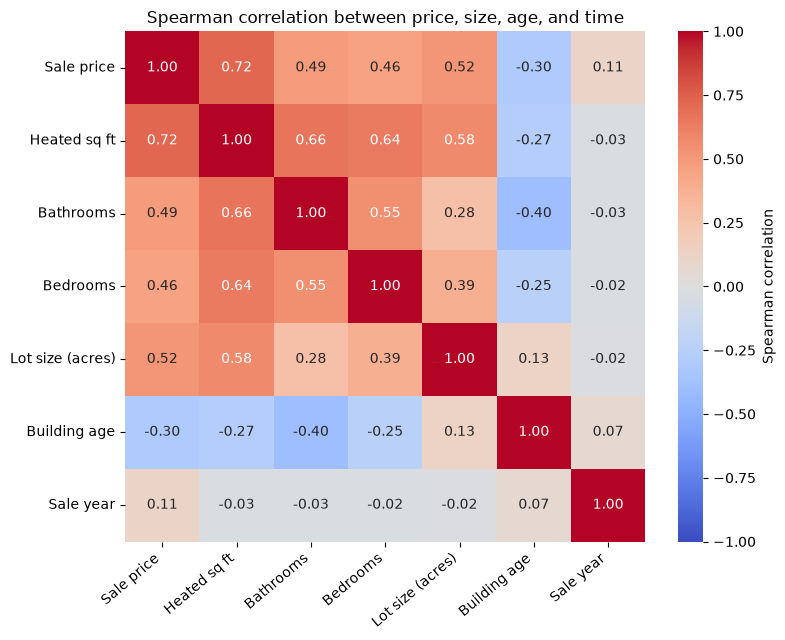

In [55]:
import seaborn as sns

spearman_matrix = biv[cols].corr(method='spearman').rename(index=corr_vars, columns=corr_vars)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    spearman_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    cbar_kws={'label': 'Spearman correlation'},
    ax=ax
)
plt.xticks(rotation=40, ha='right')
plt.title('Spearman correlation between price, size, age, and time')
plt.tight_layout()
plt.show()

**Observations:** Red cells are positive correlations and blue cells are negative. The red block in the top-left corner shows that price, square footage, bathrooms, bedrooms, and lot size all tend to rise together. Square footage is strongly related to both bathrooms (0.66) and bedrooms (0.64), so these variables partly measure the same thing: how big the house is. Building age is the only variable that shows up in blue. Its strongest link is with bathrooms (−0.40), so older homes tend to have fewer bathrooms. The sale year row is almost gray, which means the kinds of homes being sold didn't change much from 2022 to 2026.

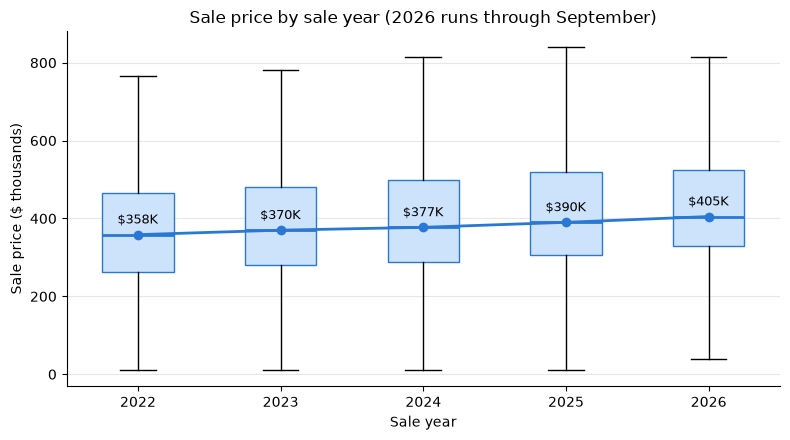

In [57]:
years = year_summary.index.tolist()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([biv.loc[biv['sale_year'] == y, 'sale_price'] / 1000 for y in years],
           tick_labels=years, showfliers=False,
           patch_artist=True, boxprops=dict(facecolor='#cde2fb', color='#2a78d6'),
           medianprops=dict(color='#2a78d6', linewidth=2))
ax.plot(range(1, len(years) + 1), year_summary['median'] / 1000,
        color='#2a78d6', marker='o', linewidth=2)
for i, m in enumerate(year_summary['median'], start=1):
    ax.annotate(f'${m / 1000:,.0f}K', (i, m / 1000), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=9)
ax.set_title('Sale price by sale year (2026 runs through September)')
ax.set_xlabel('Sale year')
ax.set_ylabel('Sale price ($ thousands)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations:** The whole price range moved up over time, not just the median. Each year the box (the middle 50% of sales) sits a little higher than the year before, and the median line climbs steadily from 358K to 405K. The height of the boxes stays about the same, so prices went up without spreading out much more. We hid the outlier points because a handful of sales above 4 million squashed the boxes and made the chart unreadable.

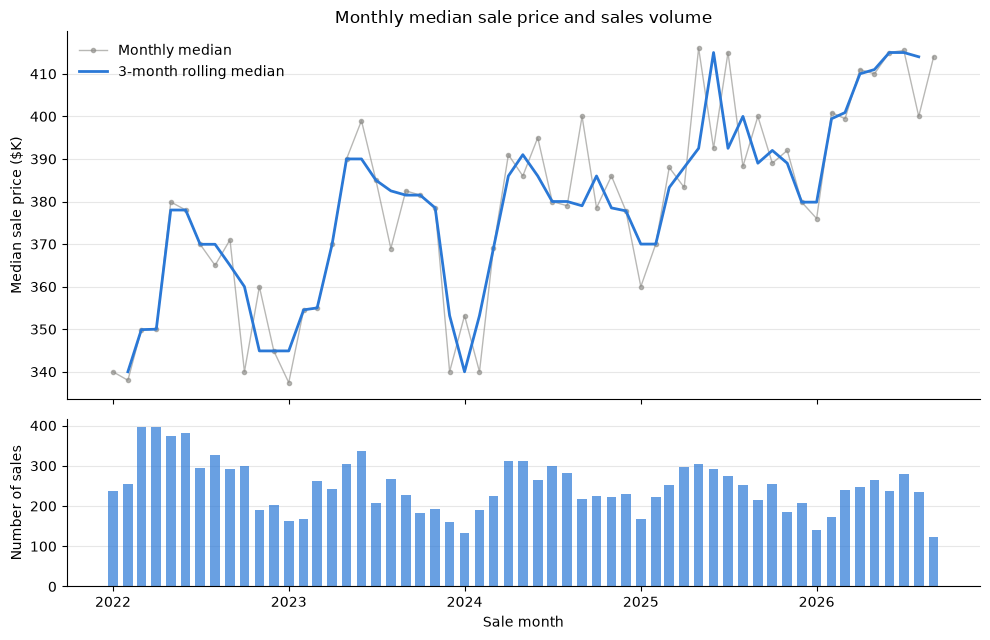

In [59]:
monthly = biv.groupby('sale_month')['sale_price'].agg(sales='count', median='median')
monthly.index = pd.to_datetime(monthly.index)
monthly['rolling_3m'] = monthly['median'].rolling(3, center=True).median()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                               gridspec_kw={'height_ratios': [2.2, 1]})
ax1.plot(monthly.index, monthly['median'] / 1000, color= '#8a8985', alpha=0.6,
         linewidth=1, marker='o', markersize=3, label='Monthly median')
ax1.plot(monthly.index, monthly['rolling_3m'] / 1000, color='#2a78d6', linewidth=2,
         label='3-month rolling median')
ax1.set_ylabel('Median sale price ($K)')
ax1.set_title('Monthly median sale price and sales volume')
ax1.legend(frameon=False)
ax1.spines[['top', 'right']].set_visible(False)
ax1.grid(axis='y', alpha=0.3)
ax1.set_axisbelow(True)

ax2.bar(monthly.index, monthly['sales'], width=20, color='#2a78d6', alpha=0.7)
ax2.set_ylabel('Number of sales')
ax2.set_xlabel('Sale month')
ax2.spines[['top', 'right']].set_visible(False)
ax2.grid(axis='y', alpha=0.3)
ax2.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations:** Prices follow the seasons. Each winter, the monthly median drops, with the lowest point at 337,450 in January 2023, and then it climbs again in spring and summer. The highest monthly medians, about 415,000, came in May 2025 and the summer of 2026. Sales volume follows a similar pattern, with more sales in spring and summer. The busiest period was spring 2022, at almost 400 sales a month. After that, volume dropped and stayed lower, even though prices kept going up. The last bar is short because our data ends on September 25, 2026.

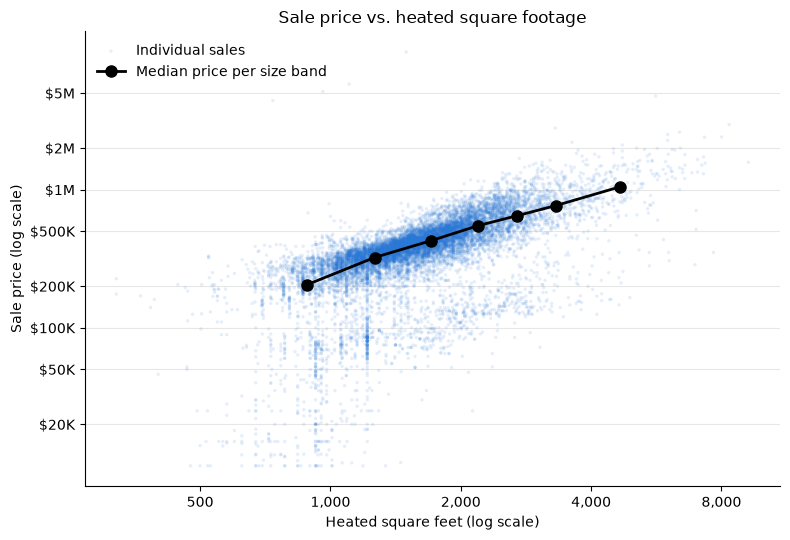

In [61]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(biv['heated_sqft'], biv['sale_price'], s=6, alpha=0.12, color='#2a78d6',
           edgecolors='none', label='Individual sales')
ax.plot(sqft_summary['median_sqft'], sqft_summary['median_price'], color='black',
        marker='o', markersize=8, linewidth=2, label='Median price per size band')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([500, 1000, 2000, 4000, 8000], ['500', '1,000', '2,000', '4,000', '8,000'])
ax.set_yticks([2e4, 5e4, 1e5, 2e5, 5e5, 1e6, 2e6, 5e6],
              ['$20K', '$50K', '$100K', '$200K', '$500K', '$1M', '$2M', '$5M'])
ax.minorticks_off()
ax.set_xlabel('Heated square feet (log scale)')
ax.set_ylabel('Sale price (log scale)')
ax.set_title(f'Sale price vs. heated square footage')
ax.legend(frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations:** Most sales fall in a tight band that rises from left to right, and the black line connecting the band medians is almost straight. This shows that price increases steadily with size. Below that band, there's a scattered group of sales between about 10,000 and 150,000 for normal-sized houses, often lined up in vertical stripes. These probably aren't normal market sales. 

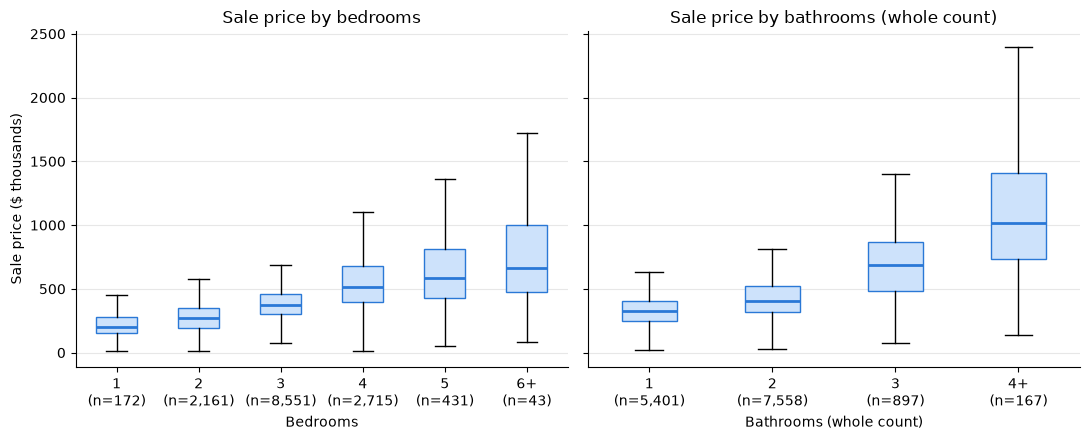

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, col, summary, title in [
    (axes[0], 'bed_group', bed_summary, 'Bedrooms'),
    (axes[1], 'bath_group', bath_summary, 'Bathrooms (whole count)'),
]:
    groups = summary.index.tolist()
    ax.boxplot(
        [biv.loc[biv[col] == g, 'sale_price'] / 1000 for g in groups],
        tick_labels=[f'{g}\n(n={n:,})' for g, n in zip(groups, summary['sales'])],
        showfliers=False,
        patch_artist=True,
        boxprops=dict(facecolor='#cde2fb', color='#2a78d6'),
        medianprops=dict(color='#2a78d6', linewidth=2),
    )
    ax.set_title(f'Sale price by {title.lower()}')
    ax.set_xlabel(title)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)

axes[0].set_ylabel('Sale price ($ thousands)')
plt.tight_layout()
plt.show()

**Observations:** Prices rise with both bedrooms and bathrooms, but the bathroom chart climbs faster, especially from 2 to 3 bathrooms. The boxes also get taller as the number of rooms goes up, so prices vary much more among large homes. There's a lot of overlap between groups. Plenty of 3-bedroom homes sell for more than some 4-bedroom homes, so the number of rooms alone doesn't decide the price. As in the yearly box plot, we hid the outlier points to keep the boxes readable.

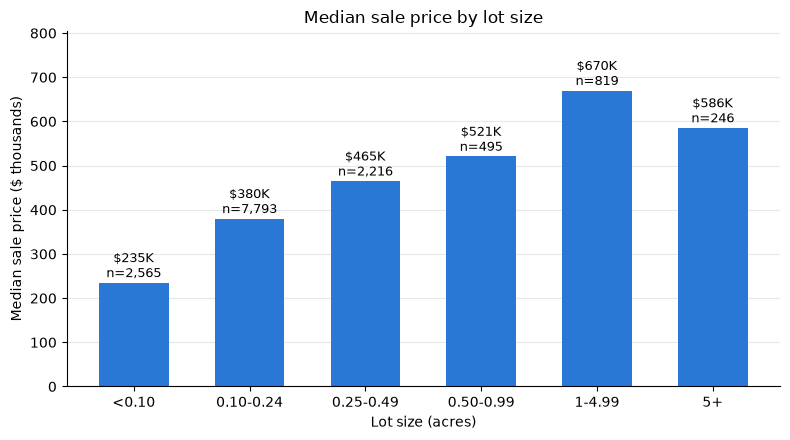

In [65]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(acre_summary.index.astype(str), acre_summary['median_price'] / 1000,
              color='#2a78d6', width=0.6)
for bar, n in zip(bars, acre_summary['sales']):
    ax.annotate(f'${bar.get_height():,.0f}K\nn={n:,}',
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                textcoords='offset points', xytext=(0, 4), ha='center', fontsize=9)
ax.set_xlabel('Lot size (acres)')
ax.set_ylabel('Median sale price ($ thousands)')
ax.set_title('Median sale price by lot size')
ax.set_ylim(0, acre_summary['median_price'].max() / 1000 * 1.2)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations:** The median price goes up with each lot-size group until 5 acres, then drops for the largest lots. The two biggest groups have only 819 and 246 sales, while most homes sit on less than a quarter acre. Because the pattern goes up and then down, one correlation number doesn't describe lot size as well as it describes square footage.

##### **Data Mining Questions**

Question 1: Are home prices rising because homes are getting bigger, or because the same space costs more?

Median prices rose from 2022 to 2026, but a rising median could simply mean buyers are purchasing larger homes. To separate these two explanations, we compare the growth in median price, median heated square footage, and median price per square foot, using 2022 as the base year (2022 = 100).

,median_price,median_sqft,median_price_per_sqft
sale_year,,,
2022,358500.0,1592.0,235.4
2023,370000.0,1584.0,244.9
2024,377300.0,1547.0,257.2
2025,390100.0,1539.0,265.4
2026,405000.0,1558.0,268.5


,median_price,median_sqft,median_price_per_sqft
sale_year,,,
2022,100.0,100.0,100.0
2023,103.2,99.5,104.0
2024,105.2,97.2,109.3
2025,108.8,96.7,112.7
2026,113.0,97.9,114.0


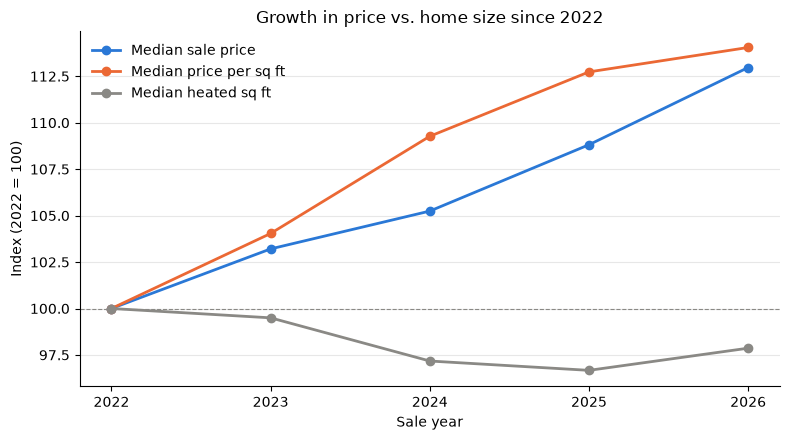

In [68]:
growth = biv.groupby('sale_year').agg(
    median_price=('sale_price', 'median'),
    median_sqft=('heated_sqft', 'median'),
    median_price_per_sqft=('price_per_sqft', 'median'),
)

# Divide every year by 2022 so all three measures start at 100
indexed = growth / growth.iloc[0] * 100
display(growth.round(1))
display(indexed.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(indexed.index, indexed['median_price'], marker='o', linewidth=2,
        color='#2a78d6', label='Median sale price')
ax.plot(indexed.index, indexed['median_price_per_sqft'], marker='o', linewidth=2,
        color='#eb6834', label='Median price per sq ft')
ax.plot(indexed.index, indexed['median_sqft'], marker='o', linewidth=2,
        color='#8a8985', label='Median heated sq ft')
ax.axhline(100, color='#8a8985', linewidth=0.8, linestyle='--')
ax.set_xticks(indexed.index)
ax.set_xlabel('Sale year')
ax.set_ylabel('Index (2022 = 100)')
ax.set_title('Growth in price vs. home size since 2022')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations:** Prices are going up because the same amount of space costs more, not because people are buying bigger homes. From 2022 to 2026, the median sale price went up 13% and the median price per square foot went up 14% (from 235 to 269). Over the same time, the typical home actually got slightly smaller, from 1,592 to 1,558 sq ft. 

Question 2: Is there a seasonal pattern in sale prices, and how large is it?

The monthly chart suggested that prices are higher in spring and summer. However, prices also rose over time, so a simple monthly average mixes the season with the long-term trend. To remove the trend, we divide each sale price by the median price of its sale year. A value of 1.03 means the sale was 3% above that year's median. We then compare these relative prices across calendar months and test whether peak-season (April–August) and off-season (November–February) prices differ.

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
sales,841.000,1010.000,1375.000,1492.000,1561.000,1512.000,1355.000,1363.0,1075.000,960.000,789.000,801.000
relative_price,0.936,0.945,0.976,0.999,1.046,1.046,1.035,1.0,1.034,0.978,1.014,0.966


Peak season median: 1.025 | Off-season median: 0.965


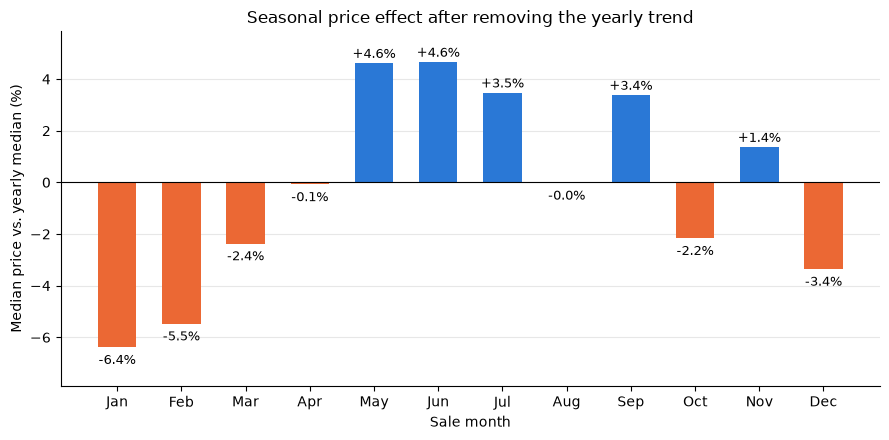

In [71]:
biv['price_vs_year_median'] = biv['sale_price'] / biv.groupby('sale_year')['sale_price'].transform('median')
biv['sale_month_num'] = biv['sale_date'].dt.month

month_effect = biv.groupby('sale_month_num').agg(
    sales=('sale_price', 'count'),
    relative_price=('price_vs_year_median', 'median'),
)
month_effect.index = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                      'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
display(month_effect.T.round(3))

peak = biv.loc[biv['sale_month_num'].isin([4, 5, 6, 7, 8]), 'price_vs_year_median']
off = biv.loc[biv['sale_month_num'].isin([11, 12, 1, 2]), 'price_vs_year_median']
u_stat, p_value = stats.mannwhitneyu(peak, off)
print(f'Peak season median: {peak.median():.3f} | Off-season median: {off.median():.3f}')

fig, ax = plt.subplots(figsize=(9, 4.5))
offsets = (month_effect['relative_price'] - 1) * 100
colors = ['#2a78d6' if v >= 0 else '#eb6834' for v in offsets]
ax.bar(month_effect.index, offsets, color=colors, width=0.6)
for x, v in enumerate(offsets):
    ax.annotate(f'{v:+.1f}%', (x, v), textcoords='offset points',
                xytext=(0, 4 if v >= 0 else -12), ha='center', fontsize=9)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylim(offsets.min() - 1.5, offsets.max() + 1.2)
ax.set_ylabel('Median price vs. yearly median (%)')
ax.set_xlabel('Sale month')
ax.set_title('Seasonal price effect after removing the yearly trend')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations:** Yes, there is a seasonal pattern. Even after removing the yearly increase, May and June sales are about 4.6% above that year's median, while January and February sales are 6.4% and 5.5% below it. Overall, April–August sales were 2.5% above the yearly median and November–February sales were 3.5% below it, a gap of about 6 percentage points. The pattern isn't perfect: August sits right at 0%, and November is slightly above. Still, on a 390,000 home, 6% is about $23,000, which matters to someone deciding when to buy or sell.

Question 3: How much value does each additional square foot add, and does it change as homes get larger?

Square footage has the strongest relationship with price, but the size-band table in our EDA suggested that larger homes cost less per square foot. To check this, we reuse the size bands from `sqft_summary`. For each band, we calculate how much the median price goes up for every 100 extra square feet compared with the previous band. We also plot the median price per square foot for each band.

,median_sqft,median_price,median_price_per_sqft,extra_value_per_100_sqft
sqft_band,,,,
"<1,000",884.0,205000.0,242.0,NaN
"1,000-1,499",1264.0,322000.0,256.0,30789.0
"1,500-1,999",1707.0,426100.0,253.0,23499.0
"2,000-2,499",2190.0,547000.0,251.0,25031.0
"2,500-2,999",2691.0,645000.0,236.0,19561.0
"3,000-3,999",3315.0,765000.0,228.0,19231.0
"4,000+",4674.0,1047500.0,212.0,20795.0


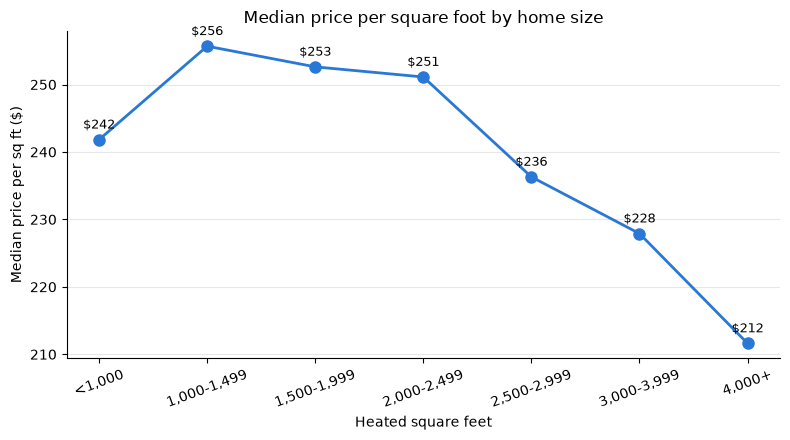

In [74]:
size_value = sqft_summary[['median_sqft', 'median_price', 'median_price_per_sqft']].copy()

size_value['extra_value_per_100_sqft'] = (
    size_value['median_price'].diff() / size_value['median_sqft'].diff() * 100
)
display(size_value.round(0))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(size_value.index.astype(str), size_value['median_price_per_sqft'],
        color='#2a78d6', marker='o', markersize=8, linewidth=2)
for x, v in enumerate(size_value['median_price_per_sqft']):
    ax.annotate(f'${v:.0f}', (x, v), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=9)
ax.set_xlabel('Heated square feet')
ax.set_ylabel('Median price per sq ft ($)')
ax.set_title('Median price per square foot by home size')
plt.xticks(rotation=20)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations:** Yes, each extra square foot adds less as homes get bigger. Going from the smallest group (under 1,000 sq ft) to the next one adds about 31,000 per 100 sq ft. For homes above 2,500 sq ft, it drops to about 19,000–21,000 per 100 sq ft. The price per square foot chart shows the same thing. It peaks at 256 for 1,000–1,499 sq ft homes, stays around 251–253 up to 2,500 sq ft, and then falls to 212 for homes over 4,000 sq ft. The smallest homes are also a little cheaper per square foot (242), possibly because many of them are condos or older homes. So mid-sized homes have the highest price per square foot, and large homes give buyers the most space for their money.

#### 5B.5 Multivariate analysis: type, year, and property characteristics